# Phase 2: Data Preprocessing

## 2.1(A) Train–test split

We split devices into 80% training and 20% test data using
`GroupShuffleSplit` with `random_state=42`. Measurements from the same
device stay in one subset to prevent overlap between train and test.
The proportion of rows may differ from 80/20 because devices have
different numbers of measurements.

Before splitting, we remove exact duplicates, normalize device IDs
and join readings with unit metadata, following Phase 1.

In [76]:
from pathlib import Path
from sklearn.base import clone
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    PowerTransformer,
    QuantileTransformer,
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder


DATA = Path("../data") if Path("../data").is_dir() else Path("data")

TEST_SIZE = 0.20
SEED = 42

In [77]:
readings = pd.read_csv(DATA / "readings.csv", sep="\t").drop_duplicates()
units = pd.read_csv(DATA / "units.csv")

readings.index.name = "reading_row_id"

ids = readings["unitId"].astype("string").str.strip()
assert ids.str.fullmatch(r"U[0-9]+", na=False).all()

readings["unit_key"] = pd.to_numeric(ids.str[1:]).astype("int64")
units["unit_key"] = pd.to_numeric(units["unitId"]).astype("int64")

assert readings[["unitId", "unit_key"]].drop_duplicates()["unit_key"].is_unique
assert units["unit_key"].is_unique
assert readings["Failure"].isin([0, 1]).all()

data = (
    readings.reset_index()
    .merge(
        units.drop(columns="unitId"),
        on="unit_key",
        how="left",
        validate="many_to_one",
        indicator="device_match",
        sort=False,
    )
    .set_index("reading_row_id")
)

data["unit_metadata_missing"] = data["device_match"].eq("left_only")

assert data.index.is_unique

pd.testing.assert_frame_equal(
    data[readings.columns].sort_index(),
    readings.sort_index(),
)
print(f"Rows after joining: {len(data):,}")
print("Join checks passed: readings and labels preserved.")

Rows after joining: 13,092
Join checks passed: readings and labels preserved.


### Split checks

We check that train and test contain different devices and rows,
that all observations are preserved, and that both classes are present.

In [78]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=SEED,
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["unit_key"])
)

train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()

assert set(train["unit_key"]).isdisjoint(test["unit_key"])
assert train.index.intersection(test.index).empty
assert set(train["Failure"]) == set(test["Failure"]) == {0, 1}

pd.testing.assert_frame_equal(
    pd.concat([train, test]).sort_index(),
    data.sort_index(),
)
print("Split checks passed:")
print("- No shared devices or rows between train and test.")
print("- All observations preserved.")
print("- Both classes present in each subset.")

Split checks passed:
- No shared devices or rows between train and test.
- All observations preserved.
- Both classes present in each subset.


In [79]:
summary = pd.DataFrame({
    name: {
        "rows": len(part),
        "rows_%": 100 * len(part) / len(data),
        "devices": part["unit_key"].nunique(),
        "Failure_0": part["Failure"].eq(0).sum(),
        "Failure_1": part["Failure"].eq(1).sum(),
        "Failure_1_%": 100 * part["Failure"].eq(1).mean(),
    }
    for name, part in {"train": train, "test": test}.items()
}).T

display(summary.style.format({
    "rows": "{:,.0f}",
    "rows_%": "{:.2f}",
    "devices": "{:,.0f}",
    "Failure_0": "{:,.0f}",
    "Failure_1": "{:,.0f}",
    "Failure_1_%": "{:.2f}",
}))

,rows,rows_%,devices,Failure_0,Failure_1,Failure_1_%
train,"10,512",80.29,"1,693","9,234","1,278",12.16
test,"2,580",19.71,424,"2,264",316,12.25


### Results

Train contains 10,512 measurements from 1,693 devices; test contains
2,580 measurements from 424 devices. The row split is 80.29% / 19.71%.
Failure rates are 12.16% in train and 12.25% in test.

Further preprocessing will be fitted on `train` and applied to `test`
without refitting. Internal validation will also be split by device.
`unit_key` and the row index will not be used as predictors.

## 2.1(B) Numerical representation

We replace invalid oil temperatures (-999) with missing values and
remove surrounding spaces from `class_duty`. Missing numerical values
are filled with training medians. Missing categories receive a separate
label; categorical attributes are one-hot encoded.

Missing-value flags preserve information about unavailable measurements.
Identifiers and raw timestamps are excluded from model inputs.

Median imputation reduces sensitivity to extreme values. One-hot
encoding avoids imposing an order on categories. Depot IDs are
treated as categories.

`owner_operator` and `installRegion` are excluded from this baseline
and will be considered during feature selection. Metadata timing
remains unverified.

In [80]:
numeric_features = [
    "motorCurrent",
    "filterDp",
    "temperatureOil",
    "pressure_reservoir",
    "vibrationRms",
    "flowmeter",
    "tempBearing",
    "discharge_dewpoint",
    "commission_year",
    "serviceHours",
]

categorical_features = [
    "codeLine",
    "class_duty",
    "id_depot",
]

missing_features = [
    "filterDp",
    "vibrationRms",
    "temperatureOil",
    "serviceHours",
]

flag_features = [
    f"{column}_missing" for column in missing_features
] + ["unit_metadata_missing"]

In [81]:
def clean_features(frame):
    frame = frame.copy()

    frame["temperatureOil"] = frame["temperatureOil"].replace(-999, np.nan)

    for column in categorical_features:
        values = frame[column].astype("string").str.strip()
        frame[column] = values.replace("", pd.NA).fillna("missing").astype(str)

    for column in missing_features:
        frame[f"{column}_missing"] = frame[column].isna().astype("int8")

    frame["unit_metadata_missing"] = (
        frame["unit_metadata_missing"].astype("int8")
    )

    return frame

In [82]:
def make_preprocessor(numeric_transformer=None):
    numeric_steps = [
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        ).set_output(transform="pandas")),
    ]

    if numeric_transformer is not None:
        numeric_steps.append(("transformer", clone(numeric_transformer)))

    columns = ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(numeric_steps), numeric_features),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                categorical_features,
            ),
            ("flags", "passthrough", flag_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    return Pipeline([
        ("clean", FunctionTransformer(clean_features)),
        ("columns", columns),
    ])


preprocessor = make_preprocessor()

In [83]:
X_train = train.drop(columns="Failure")
y_train = train["Failure"].copy()

train_values = preprocessor.fit_transform(X_train)

X_train_ready = pd.DataFrame(
    train_values,
    columns=preprocessor.named_steps["columns"].get_feature_names_out(),
    index=X_train.index,
)

assert X_train_ready.index.equals(y_train.index)
assert X_train_ready.columns.is_unique
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_ready.dtypes)
assert np.isfinite(X_train_ready.to_numpy()).all()

print(f"Training data: {X_train_ready.shape[0]:,} rows, "
      f"{X_train_ready.shape[1]} features.")
print("Checks passed: numerical values only, no missing or infinite values.")

display(X_train_ready.head())

clean_train = clean_features(X_train)

imputation_summary = pd.DataFrame({
    "missing_before": clean_train[numeric_features].isna().sum(),
    "fill_value": (
        preprocessor.named_steps["columns"]
        .named_transformers_["numeric"]
        .named_steps["imputer"]
        .statistics_
    ),
})

display(imputation_summary.round(2))

Training data: 10,512 rows, 154 features.
Checks passed: numerical values only, no missing or infinite values.


,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,commission_year,serviceHours,...,id_depot_96.0,id_depot_97.0,id_depot_98.0,id_depot_99.0,id_depot_missing,filterDp_missing,vibrationRms_missing,temperatureOil_missing,serviceHours_missing,unit_metadata_missing
reading_row_id,,,,,,,,,,,,,,,,,,,,,
0,4.76770,28.08519,47.03756,8.71892,3.54971,31.62776,66.80334,1.83965,2021.0,11693.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.43105,37.32422,66.59793,9.18652,3.10090,26.41965,67.47312,6.77918,2019.0,18726.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.86624,21.25867,69.81401,8.43531,2.96697,30.50532,76.92666,6.36091,2020.0,14315.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,7.95578,20.55112,65.27601,8.78518,3.34915,29.34461,58.94879,9.54776,2021.0,11761.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,3.00923,40.10576,52.80288,8.20098,2.40980,26.94215,70.89081,2.55234,2023.0,4661.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,missing_before,fill_value
motorCurrent,0,5.04
filterDp,436,21.38
temperatureOil,31,54.81
pressure_reservoir,0,8.71
vibrationRms,420,2.72
flowmeter,0,28.07
tempBearing,0,65.04
discharge_dewpoint,0,7.99
commission_year,101,2021.00
serviceHours,600,11563.40


The baseline contains numerical features without missing or infinite
values. Row order and target alignment are preserved.

Scaling and distribution transformations will be compared next.
During validation, preprocessing will be fitted within each training
fold using the original `X_train`.

## 2.1(C) Scaling and transformations

We compare StandardScaler, MinMaxScaler, RobustScaler, Yeo–Johnson
and QuantileTransformer.

Yeo–Johnson and quantile transformation are applied to sensors and
service hours; commissioning year is only standardized. Category
encoding and missing-value flags remain the same across variants.

All methods are fitted on train. Tables compare scales and skewness;
histograms show changes in distribution shape.

In [84]:

continuous_features = [
    column for column in numeric_features
    if column != "commission_year"
]


def distribution_transformer(transformer):
    return ColumnTransformer(
        transformers=[
            ("continuous", transformer, continuous_features),
            ("year", StandardScaler(), ["commission_year"]),
        ],
        verbose_feature_names_out=False,
    )


transformers = {
    "Standard": StandardScaler(),
    "MinMax": MinMaxScaler(),
    "Robust": RobustScaler(),
    "Yeo-Johnson": distribution_transformer(
        Pipeline([
            ("power", PowerTransformer(
                method="yeo-johnson",
                standardize=False,
            )),
            ("scale", StandardScaler()),
        ])
    ),
    "Quantile": distribution_transformer(
        QuantileTransformer(
            n_quantiles=200,
            output_distribution="normal",
            random_state=SEED,
        )
    ),
}

In [85]:
processed_train = {"Median only": X_train_ready}
fitted_preprocessors = {}

for name, transformer in transformers.items():
    processor = make_preprocessor(transformer)
    values = processor.fit_transform(X_train)

    frame = pd.DataFrame(
        values,
        columns=processor.named_steps["columns"].get_feature_names_out(),
        index=X_train.index,
    )

    assert frame.index.equals(X_train.index)
    assert frame.columns.is_unique
    assert set(frame.columns) == set(X_train_ready.columns)
    assert np.isfinite(frame.to_numpy()).all()

    processed_train[name] = frame
    fitted_preprocessors[name] = processor

print("All variants preserve rows and features and contain finite numerical values.")

All variants preserve rows and features and contain finite numerical values.


In [86]:
plot_features = [
    "motorCurrent",
    "filterDp",
    "vibrationRms",
    "serviceHours",
]

scaling_summary = pd.DataFrame([
    {
        "feature": feature,
        "method": method,
        "min": frame[feature].min(),
        "max": frame[feature].max(),
        "mean": frame[feature].mean(),
        "std": frame[feature].std(ddof=0),
        "median": frame[feature].median(),
        "IQR": (
            frame[feature].quantile(0.75)
            - frame[feature].quantile(0.25)
        ),
    }
    for feature in plot_features
    for method, frame in processed_train.items()
    if method in ["Median only", "Standard", "MinMax", "Robust"]
]).set_index(["feature", "method"])

display(scaling_summary.round(3))

min        max       mean       std     median  \
feature      method                                                             
motorCurrent Median only     0.000     99.000      5.256     3.658      5.035   
             Standard       -1.437     25.624     -0.000     1.000     -0.060   
             MinMax          0.000      1.000      0.053     0.037      0.051   
             Robust         -1.755     32.750      0.077     1.275      0.000   
filterDp     Median only     7.183    120.000     24.014    11.113     21.384   
             Standard       -1.515      8.637     -0.000     1.000     -0.237   
             MinMax          0.000      1.000      0.149     0.099      0.126   
             Robust         -1.198      8.319      0.222     0.937      0.000   
vibrationRms Median only     0.500     14.000      3.047     1.592      2.719   
             Standard       -1.600      6.878     -0.000     1.000     -0.206   
             MinMax          0.000      1.000      0.189     0.118      0.164   
             Robust         -1.264      6.428      0.187     0.907      0.000   
serviceHours Median only  1465.600  45000.000  13857.039  8615.574  11563.400   
             Standard       -1.438      3.615     -0.000     1.000     -0.266   
             MinMax          0.000      1.000      0.285     0.198      0.232   
             Robust         -1.120      3.708      0.254     0.956      0.000   

                               IQR  
feature      method                 
motorCurrent Median only     2.869  
             Standard        0.784  
             MinMax          0.029  
             Robust          1.000  
filterDp     Median only    11.854  
             Standard        1.067  
             MinMax          0.105  
             Robust          1.000  
vibrationRms Median only     1.755  
             Standard        1.102  
             MinMax          0.130  
             Robust          1.000  
serviceHours Median only  9016.575  
             Standard        1.047  
             MinMax          0.207  
             Robust          1.000

StandardScaler produces zero means and unit standard deviations.
RobustScaler produces zero medians and unit interquartile ranges.

MinMaxScaler maps training values to [0, 1]. For motorCurrent, the
maximum of 99 compresses the central values: the scaled IQR is 0.029.
None of these scalers removes extreme values.

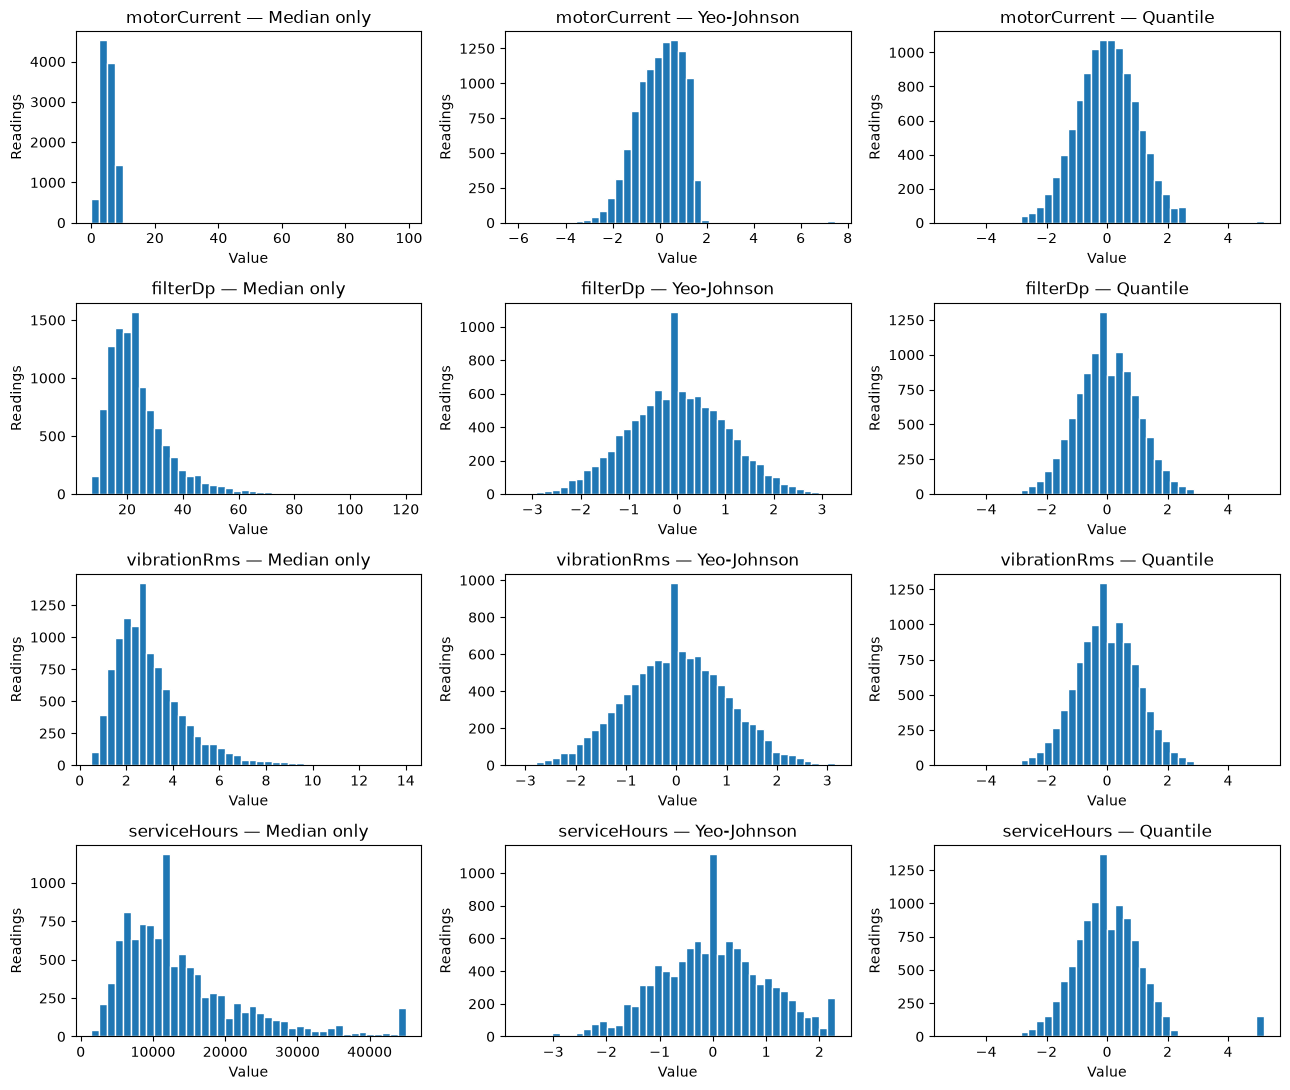

In [87]:
methods = ["Median only", "Yeo-Johnson", "Quantile"]

fig, axes = plt.subplots(4, 3, figsize=(13, 11))

for row, feature in enumerate(plot_features):
    for col, method in enumerate(methods):
        ax = axes[row, col]
        ax.hist(processed_train[method][feature], bins=40, edgecolor="white")
        ax.set_title(f"{feature} — {method}")
        ax.set_xlabel("Value")
        ax.set_ylabel("Readings")

fig.tight_layout()
plt.show()

In [88]:
skewness = pd.DataFrame({
    method: processed_train[method][plot_features].skew()
    for method in methods
})

display(skewness.round(3))

,Median only,Yeo-Johnson,Quantile
motorCurrent,19.210,-0.043,0.108
filterDp,1.915,0.007,-0.010
vibrationRms,1.719,0.005,0.027
serviceHours,1.554,0.000,1.096


Yeo–Johnson reduced skewness close to zero for all four attributes.
QuantileTransformer reduced skewness for motorCurrent, filterDp and
vibrationRms, but serviceHours remained right-skewed (1.096).

These results describe distribution shape. Predictive performance
will be compared using validation grouped by device.

### 2.1(D) Preprocessing decisions

We keep outliers: their removal in Phase 1 disproportionately excluded
failure readings. Missing numerical values are filled with training
medians, with flags preserving missingness information. Categories
are one-hot encoded; identifiers and raw timestamps are excluded.

Scalers changed feature ranges without changing distribution shape.
Yeo–Johnson reduced skewness most consistently across the four inspected
attributes. The final variant will be selected through validation
grouped by device.

Preprocessing is fitted on train only.